# Sleep Staging — 08: Contexto temporal

**Objetivo:** evaluar si incorporar información de epochs vecinos mejora la clasificación respecto de la CNN de NB6, que trabaja con cada epoch de forma independiente.

Para mantener el experimento simple, se reutiliza la representación aprendida por la 1D-CNN de NB6. Cada epoch se transforma en un embedding y luego se construyen secuencias de cinco epochs consecutivos:

```text
t-2, t-1, t, t+1, t+2
```

Una BiGRU recibe esa secuencia y predice la etapa del epoch central `t`.

La CNN se mantiene congelada en esta primera prueba. Así, la comparación se concentra en el efecto del contexto temporal y no en cambios adicionales de arquitectura.

---
## 1. Setup

Se reutilizan directamente los artefactos generados por NB6: cache de señales, metadata, split por sujeto, normalización y checkpoint de la CNN.

In [2]:
from pathlib import Path
import json
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.utils.class_weight import compute_class_weight

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

DATA_DIR = Path("../data/processed")
RESULTS_DIR = Path("../reports/results")
FIGURES_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")

for directory in (RESULTS_DIR, FIGURES_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Artefactos de NB6
CACHE_X_PATH = DATA_DIR / "dl_signals.npy"
CACHE_META_PATH = DATA_DIR / "dl_metadata.parquet"
NORM_PATH = RESULTS_DIR / "dl_channel_normalization.json"
DL_SPLIT_PATH = RESULTS_DIR / "dl_subject_split.json"
CNN_MODEL_PATH = MODELS_DIR / "dl_cnn_baseline.pt"
CNN_PREDICTIONS_PATH = RESULTS_DIR / "dl_cnn_holdout_predictions.parquet"

# Artefactos de NB8
EMBEDDINGS_PATH = DATA_DIR / "dl_cnn_embeddings.npy"
TEMPORAL_INDEX_PATH = DATA_DIR / "dl_temporal_sequence_index.parquet"
TEMPORAL_MODEL_PATH = MODELS_DIR / "dl_temporal_bigru.pt"
HISTORY_PATH = RESULTS_DIR / "dl_temporal_training_history.csv"
METRICS_PATH = RESULTS_DIR / "dl_temporal_holdout_metrics.json"
PREDICTIONS_PATH = RESULTS_DIR / "dl_temporal_holdout_predictions.parquet"
COMPARISON_PATH = RESULTS_DIR / "dl_temporal_comparison.csv"
CLASS_COMPARISON_PATH = RESULTS_DIR / "dl_temporal_class_comparison.csv"
TRANSITION_COMPARISON_PATH = RESULTS_DIR / "dl_temporal_transition_comparison.csv"
CM_PATH = FIGURES_DIR / "dl_temporal_confusion_matrix.png"
HISTORY_FIG_PATH = FIGURES_DIR / "dl_temporal_training_history.png"

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_ORDER = list(STAGE_MAP)
STAGE_NAMES = [STAGE_MAP[idx] for idx in STAGE_ORDER]

CONTEXT_SIZE = 5
HALF_CONTEXT = CONTEXT_SIZE // 2
EMBEDDING_DIM = 128
HIDDEN_DIM = 64
BATCH_SIZE = 256
MAX_EPOCHS = 25
PATIENCE = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch: {torch.__version__}")
print(f"Device:  {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU:     {torch.cuda.get_device_name(0)}")

PyTorch: 2.11.0+cu128
Device:  cuda
GPU:     NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [3]:
required_paths = [
    CACHE_X_PATH,
    CACHE_META_PATH,
    NORM_PATH,
    DL_SPLIT_PATH,
    CNN_MODEL_PATH,
]

missing = [path for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Faltan artefactos de NB6:\n" +
        "\n".join(f"- {path}" for path in missing)
    )

signals = np.load(CACHE_X_PATH, mmap_mode="r")
metadata = pd.read_parquet(CACHE_META_PATH).reset_index(drop=True)

assert len(signals) == len(metadata)
assert np.array_equal(metadata["epoch_global"].to_numpy(), np.arange(len(metadata)))

with open(NORM_PATH, "r", encoding="utf-8") as file:
    norm_info = json.load(file)

channel_mean = np.asarray(norm_info["channel_mean_uv"], dtype=np.float32)
channel_std = np.asarray(norm_info["channel_std_uv"], dtype=np.float32)

with open(DL_SPLIT_PATH, "r", encoding="utf-8") as file:
    split_info = json.load(file)

train_subjects = set(split_info["train_subjects"])
val_subjects = set(split_info["validation_subjects"])
test_subjects = set(split_info["test_subjects"])

assert train_subjects.isdisjoint(val_subjects)
assert train_subjects.isdisjoint(test_subjects)
assert val_subjects.isdisjoint(test_subjects)

print(f"Señales:    {signals.shape}")
print(f"Epochs:     {len(metadata):,}")
print(f"Sujetos:    {metadata['subject'].nunique()}")
print(f"Train:      {len(train_subjects)} sujetos")
print(f"Validation: {len(val_subjects)} sujetos")
print(f"Test:       {len(test_subjects)} sujetos")

Señales:    (135471, 7, 3000)
Epochs:     135,471
Sujetos:    149
Train:      95 sujetos
Validation: 24 sujetos
Test:       30 sujetos


---
## 2. CNN de NB6 como encoder

Se reconstruye la misma 1D-CNN de NB6 y se cargan sus pesos entrenados. Para esta notebook se utiliza solamente la salida del bloque convolucional, antes de la capa final de clasificación.

El resultado es un vector de 128 valores por epoch.

In [4]:
class SleepCNN(nn.Module):
    def __init__(self, n_channels=7, n_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(n_channels, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(4),

            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(4),

            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(128, n_classes),
        )

    def encode(self, x):
        return self.features(x).squeeze(-1)

    def forward(self, x):
        return self.classifier(self.features(x))


cnn = SleepCNN(
    n_channels=signals.shape[1],
    n_classes=len(STAGE_NAMES),
).to(DEVICE)

cnn.load_state_dict(
    torch.load(CNN_MODEL_PATH, map_location=DEVICE)
)
cnn.eval()

for parameter in cnn.parameters():
    parameter.requires_grad = False

print(cnn)
print("Parámetros CNN:", sum(p.numel() for p in cnn.parameters()))

SleepCNN(
  (features): Sequential(
    (0): Conv1d(7, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=128, out_features=5, bias=True)
  )
)
Parámetros CNN: 58181


---
## 3. Embeddings por epoch

Los embeddings se calculan una sola vez y se guardan en un `.npy`. El archivo ocupa mucho menos que las señales originales y puede abrirse con `mmap` en las ejecuciones siguientes.

La normalización es exactamente la misma que se utilizó en NB6.

In [5]:
class SignalDataset(Dataset):
    def __init__(self, signals, indices, mean, std):
        self.signals = signals
        self.indices = np.asarray(indices, dtype=np.int64)
        self.mean = np.asarray(mean, dtype=np.float32)[:, None]
        self.std = np.asarray(std, dtype=np.float32)[:, None]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        idx = self.indices[item]
        x = np.asarray(self.signals[idx], dtype=np.float32)
        x = (x - self.mean) / self.std
        return torch.from_numpy(x)


@torch.no_grad()
def build_embedding_cache(force=False):
    if EMBEDDINGS_PATH.exists() and not force:
        embeddings = np.load(EMBEDDINGS_PATH, mmap_mode="r")
        if embeddings.shape == (len(metadata), EMBEDDING_DIM):
            print("Se reutiliza el cache de embeddings.")
            return embeddings

    print("Calculando embeddings de la CNN...")

    embeddings_mm = np.lib.format.open_memmap(
        EMBEDDINGS_PATH,
        mode="w+",
        dtype=np.float32,
        shape=(len(metadata), EMBEDDING_DIM),
    )

    dataset = SignalDataset(
        signals,
        np.arange(len(metadata)),
        channel_mean,
        channel_std,
    )
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )

    offset = 0
    for batch_number, xb in enumerate(loader, start=1):
        xb = xb.to(DEVICE, non_blocking=True)
        batch_embeddings = cnn.encode(xb).cpu().numpy().astype(np.float32)

        end = offset + len(batch_embeddings)
        embeddings_mm[offset:end] = batch_embeddings
        offset = end

        if batch_number % 100 == 0 or batch_number == len(loader):
            print(f"{offset:>6}/{len(metadata)} epochs")

    embeddings_mm.flush()
    del embeddings_mm

    return np.load(EMBEDDINGS_PATH, mmap_mode="r")


embeddings = build_embedding_cache()
print("Embeddings:", embeddings.shape)

Se reutiliza el cache de embeddings.
Embeddings: (135471, 128)


---
## 4. Secuencias temporales

Las ventanas se construyen por sujeto y se aceptan solamente cuando los cinco epochs son realmente consecutivos.

Se verifican dos condiciones:

- `source_epoch_index` aumenta de uno en uno;
- `recording_onset_s` aumenta de 30 en 30 segundos.

Esto evita unir artificialmente segmentos separados por un epoch descartado o por un gap en las anotaciones.

In [6]:
def build_temporal_index(metadata, context_size=5):
    half = context_size // 2
    rows = []

    for subject, subject_df in metadata.groupby("subject", sort=True):
        subject_df = subject_df.sort_values("epoch_global").reset_index(drop=True)

        global_idx = subject_df["epoch_global"].to_numpy(dtype=np.int64)
        source_idx = subject_df["source_epoch_index"].to_numpy(dtype=np.int64)
        onset = subject_df["recording_onset_s"].to_numpy(dtype=np.float64)
        labels = subject_df["label"].to_numpy(dtype=np.int64)
        qc_status = subject_df["qc_status"].astype(str).to_numpy()

        for center in range(half, len(subject_df) - half):
            start = center - half
            stop = center + half + 1

            source_window = source_idx[start:stop]
            onset_window = onset[start:stop]

            if not np.all(np.diff(source_window) == 1):
                continue
            if not np.allclose(np.diff(onset_window), 30.0, atol=1e-3):
                continue

            sequence_global_idx = global_idx[start:stop]

            rows.append({
                "subject": subject,
                "center_epoch_global": int(global_idx[center]),
                "source_epoch_index": int(source_idx[center]),
                "recording_onset_s": float(onset[center]),
                "label": int(labels[center]),
                "qc_status": str(qc_status[center]),
                "sequence_indices": sequence_global_idx.tolist(),
                "is_transition": bool(
                    labels[center - 1] != labels[center]
                    or labels[center + 1] != labels[center]
                ),
            })

    return pd.DataFrame(rows)


if TEMPORAL_INDEX_PATH.exists():
    temporal_index = pd.read_parquet(TEMPORAL_INDEX_PATH)
else:
    temporal_index = build_temporal_index(metadata, CONTEXT_SIZE)
    temporal_index.to_parquet(TEMPORAL_INDEX_PATH, index=False)

print(f"Secuencias válidas: {len(temporal_index):,}")
print(f"Sujetos:            {temporal_index['subject'].nunique()}")
display(temporal_index.head())

Secuencias válidas: 134,866
Sujetos:            149


,subject,center_epoch_global,source_epoch_index,recording_onset_s,label,qc_status,sequence_indices,is_transition
0,SN001,2,2,60.0,0,ok,"[0, 1, 2, 3, 4]",False
1,SN001,3,3,90.0,0,ok,"[1, 2, 3, 4, 5]",False
2,SN001,4,4,120.0,0,ok,"[2, 3, 4, 5, 6]",False
3,SN001,5,5,150.0,0,ok,"[3, 4, 5, 6, 7]",False
4,SN001,6,6,180.0,0,ok,"[4, 5, 6, 7, 8]",False


In [7]:
sequence_summary = pd.DataFrame({
    "partition": ["train", "validation", "test"],
    "subjects": [len(train_subjects), len(val_subjects), len(test_subjects)],
    "sequences": [
        temporal_index["subject"].isin(train_subjects).sum(),
        temporal_index["subject"].isin(val_subjects).sum(),
        temporal_index["subject"].isin(test_subjects).sum(),
    ],
})
display(sequence_summary)

stage_distribution = (
    temporal_index["label"]
    .value_counts(normalize=True)
    .sort_index()
    .rename(index=STAGE_MAP)
    .rename("proportion")
)
display(stage_distribution.to_frame())

n_transition = int(temporal_index["is_transition"].sum())
print(
    f"Epochs cercanos a transición: {n_transition:,} "
    f"({100 * n_transition / len(temporal_index):.1f}%)"
)

,partition,subjects,sequences
0,train,95,86922
1,validation,24,21436
2,test,30,26508


,proportion
label,
W,0.170399
N1,0.109835
N2,0.366408
N3,0.197715
REM,0.155643


Epochs cercanos a transición: 34,398 (25.5%)


---
## 5. Dataset temporal

El dataset no copia las secuencias a memoria. Cada ejemplo guarda solamente los cinco índices que corresponden a sus embeddings y los recupera desde el archivo `mmap` cuando se arma el batch.

In [8]:
class TemporalEmbeddingDataset(Dataset):
    def __init__(self, embeddings, index_df):
        self.embeddings = embeddings
        self.sequence_indices = np.stack(
            index_df["sequence_indices"].apply(np.asarray).to_numpy()
        ).astype(np.int64)
        self.labels = index_df["label"].to_numpy(dtype=np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, item):
        indices = self.sequence_indices[item]
        x = np.asarray(self.embeddings[indices], dtype=np.float32)
        y = self.labels[item]
        return torch.from_numpy(x), torch.tensor(y, dtype=torch.long)


def partition_index(subjects):
    return temporal_index[
        temporal_index["subject"].isin(subjects)
    ].reset_index(drop=True)


train_index = partition_index(train_subjects)
val_index = partition_index(val_subjects)
test_index = partition_index(test_subjects)

train_dataset = TemporalEmbeddingDataset(embeddings, train_index)
val_dataset = TemporalEmbeddingDataset(embeddings, val_index)
test_dataset = TemporalEmbeddingDataset(embeddings, test_index)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print(f"Train:      {len(train_dataset):>6} secuencias")
print(f"Validation: {len(val_dataset):>6} secuencias")
print(f"Test:       {len(test_dataset):>6} secuencias")

Train:       86922 secuencias
Validation:  21436 secuencias
Test:        26508 secuencias


---
## 6. Modelo temporal

Se utiliza una BiGRU de una sola capa. La entrada tiene forma `(5, 128)` y la salida usada para clasificar es la correspondiente al epoch central.

La red es bidireccional porque el problema se evalúa sobre registros completos: para clasificar un epoch se permite utilizar tanto contexto previo como posterior.

In [9]:
class TemporalBiGRU(nn.Module):
    def __init__(self, input_dim=128, hidden_dim=64, n_classes=5):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True,
        )
        self.dropout = nn.Dropout(0.30)
        self.classifier = nn.Linear(hidden_dim * 2, n_classes)

    def forward(self, x):
        sequence_output, _ = self.gru(x)
        center_output = sequence_output[:, HALF_CONTEXT, :]
        return self.classifier(self.dropout(center_output))


model = TemporalBiGRU(
    input_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    n_classes=len(STAGE_NAMES),
).to(DEVICE)

print(model)
print(
    "Parámetros entrenables:",
    sum(p.numel() for p in model.parameters() if p.requires_grad),
)

TemporalBiGRU(
  (gru): GRU(128, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=5, bias=True)
)
Parámetros entrenables: 75141


In [10]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.asarray(STAGE_ORDER),
    y=train_index["label"].to_numpy(),
)
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)

weights_df = pd.DataFrame({
    "stage": STAGE_NAMES,
    "weight": class_weights.cpu().numpy(),
})
display(weights_df.round(3))

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

,stage,weight
0,W,1.131
1,N1,1.813
2,N2,0.549
3,N3,1.039
4,REM,1.284


---
## 7. Entrenamiento

Se usa la misma lógica general de NB6: pesos de clase, Adam y early stopping según Macro-F1 de validation.

El holdout no participa del entrenamiento ni de la selección de época.

In [11]:
def predict_loader(model, loader):
    model.eval()

    y_true = []
    y_pred = []
    probabilities = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=True)

            logits = model(xb)
            probs = torch.softmax(logits, dim=1)
            pred = probs.argmax(dim=1)

            y_true.append(yb.numpy())
            y_pred.append(pred.cpu().numpy())
            probabilities.append(probs.cpu().numpy())

    return (
        np.concatenate(y_true),
        np.concatenate(y_pred),
        np.concatenate(probabilities),
    )


def evaluate_loader(model, loader):
    y_true, y_pred, _ = predict_loader(model, loader)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }

In [12]:
history = []
best_macro_f1 = -np.inf
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()

    running_loss = 0.0
    n_train = 0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(yb)
        n_train += len(yb)

    train_loss = running_loss / n_train
    val_metrics = evaluate_loader(model, val_loader)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_balanced_accuracy": val_metrics["balanced_accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
    })

    print(
        f"Epoch {epoch:02d} | "
        f"loss={train_loss:.4f} | "
        f"val Macro-F1={val_metrics['macro_f1']:.4f} | "
        f"val BalAcc={val_metrics['balanced_accuracy']:.4f}"
    )

    if val_metrics["macro_f1"] > best_macro_f1:
        best_macro_f1 = val_metrics["macro_f1"]
        epochs_without_improvement = 0
        torch.save(model.state_dict(), TEMPORAL_MODEL_PATH)
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

history = pd.DataFrame(history)
history.to_csv(HISTORY_PATH, index=False)

model.load_state_dict(
    torch.load(TEMPORAL_MODEL_PATH, map_location=DEVICE)
)

display(history)

Epoch 01 | loss=0.4630 | val Macro-F1=0.7686 | val BalAcc=0.7818
Epoch 02 | loss=0.3960 | val Macro-F1=0.7689 | val BalAcc=0.7840
Epoch 03 | loss=0.3905 | val Macro-F1=0.7651 | val BalAcc=0.7791
Epoch 04 | loss=0.3867 | val Macro-F1=0.7678 | val BalAcc=0.7808
Epoch 05 | loss=0.3828 | val Macro-F1=0.7731 | val BalAcc=0.7855
Epoch 06 | loss=0.3814 | val Macro-F1=0.7716 | val BalAcc=0.7834
Epoch 07 | loss=0.3799 | val Macro-F1=0.7689 | val BalAcc=0.7881
Epoch 08 | loss=0.3769 | val Macro-F1=0.7621 | val BalAcc=0.7786
Epoch 09 | loss=0.3780 | val Macro-F1=0.7725 | val BalAcc=0.7852
Epoch 10 | loss=0.3754 | val Macro-F1=0.7753 | val BalAcc=0.7897
Epoch 11 | loss=0.3732 | val Macro-F1=0.7713 | val BalAcc=0.7843
Epoch 12 | loss=0.3733 | val Macro-F1=0.7774 | val BalAcc=0.7885
Epoch 13 | loss=0.3732 | val Macro-F1=0.7692 | val BalAcc=0.7792
Epoch 14 | loss=0.3721 | val Macro-F1=0.7757 | val BalAcc=0.7901
Epoch 15 | loss=0.3711 | val Macro-F1=0.7739 | val BalAcc=0.7862
Epoch 16 | loss=0.3692 | 

,epoch,train_loss,val_accuracy,val_balanced_accuracy,val_macro_f1
0,1,0.462982,0.785921,0.781757,0.768620
1,2,0.395979,0.785361,0.784043,0.768946
2,3,0.390469,0.776777,0.779148,0.765144
3,4,0.386744,0.785688,0.780846,0.767768
4,5,0.382804,0.783728,0.785537,0.773077
5,6,0.381393,0.790679,0.783380,0.771608
6,7,0.379857,0.780789,0.788055,0.768948
7,8,0.376898,0.774352,0.778574,0.762056
8,9,0.377984,0.789653,0.785204,0.772509
9,10,0.375374,0.787694,0.789723,0.775259


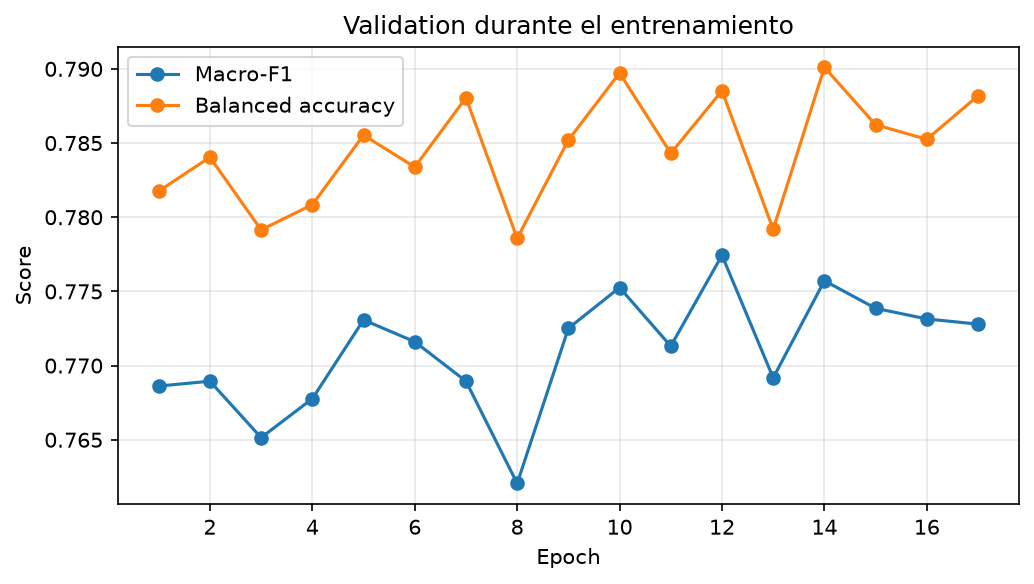

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    history["epoch"],
    history["val_macro_f1"],
    marker="o",
    label="Macro-F1",
)
ax.plot(
    history["epoch"],
    history["val_balanced_accuracy"],
    marker="o",
    label="Balanced accuracy",
)
ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_title("Validation durante el entrenamiento")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig(HISTORY_FIG_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)

Image(filename=str(HISTORY_FIG_PATH))

---
## 8. Evaluación sobre holdout

El modelo seleccionado por validation se evalúa una sola vez sobre los sujetos de test. Se mantienen las métricas utilizadas en el resto del proyecto: accuracy, balanced accuracy, Macro-F1 y resultados por clase.

In [14]:
y_true, y_pred, y_prob = predict_loader(model, test_loader)

holdout_metrics = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_true, y_pred)
    ),
    "macro_f1": float(
        f1_score(y_true, y_pred, average="macro")
    ),
    "n_test_sequences": int(len(y_true)),
    "n_test_subjects": int(test_index["subject"].nunique()),
    "context_size": CONTEXT_SIZE,
}

with open(METRICS_PATH, "w", encoding="utf-8") as file:
    json.dump(holdout_metrics, file, indent=2)

print(json.dumps(holdout_metrics, indent=2))
print()
print(
    classification_report(
        y_true,
        y_pred,
        labels=STAGE_ORDER,
        target_names=STAGE_NAMES,
        digits=4,
        zero_division=0,
    )
)

{
  "accuracy": 0.78346159649917,
  "balanced_accuracy": 0.7856189129854686,
  "macro_f1": 0.7713968518323624,
  "n_test_sequences": 26508,
  "n_test_subjects": 30,
  "context_size": 5
}

              precision    recall  f1-score   support

           W     0.8634    0.7881    0.8241      4252
          N1     0.4310    0.6384    0.5146      3034
          N2     0.8702    0.7379    0.7986     10162
          N3     0.8369    0.8733    0.8547      5013
         REM     0.8410    0.8903    0.8650      4047

    accuracy                         0.7835     26508
   macro avg     0.7685    0.7856    0.7714     26508
weighted avg     0.8081    0.7835    0.7909     26508



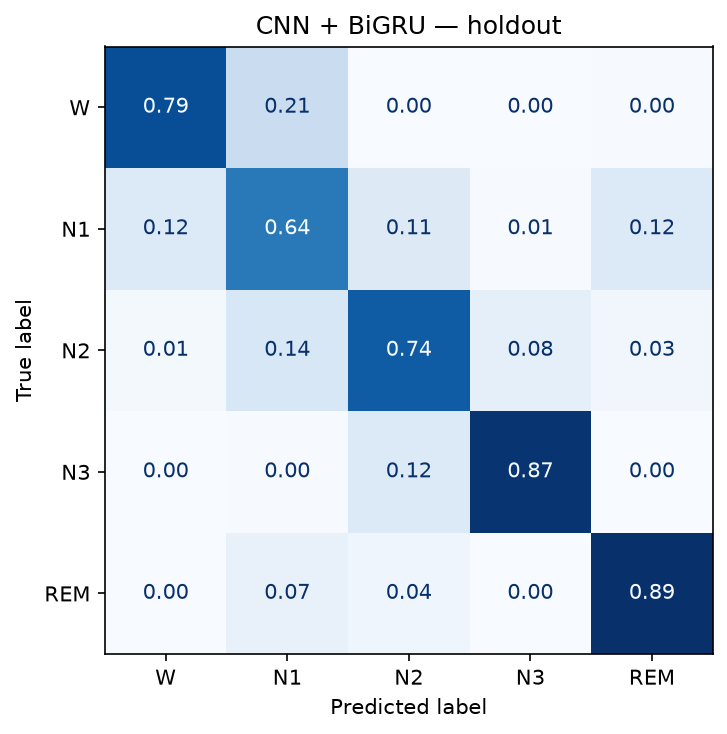

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=STAGE_ORDER,
    display_labels=STAGE_NAMES,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("CNN + BiGRU — holdout")
plt.tight_layout()
fig.savefig(CM_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)

Image(filename=str(CM_PATH))

In [16]:
predictions = test_index[
    [
        "subject",
        "center_epoch_global",
        "source_epoch_index",
        "recording_onset_s",
        "qc_status",
        "is_transition",
        "label",
    ]
].copy()

predictions = predictions.rename(columns={"label": "y_true"})
predictions["y_pred"] = y_pred

for class_idx, stage_name in STAGE_MAP.items():
    predictions[f"prob_{stage_name}"] = y_prob[:, class_idx]

predictions.to_parquet(PREDICTIONS_PATH, index=False)
display(predictions.head())

,subject,center_epoch_global,source_epoch_index,recording_onset_s,qc_status,is_transition,y_true,y_pred,prob_W,prob_N1,prob_N2,prob_N3,prob_REM
0,SN010,8289,2,60.0,ok,False,0,0,0.993658,0.006231,0.000044,0.000005,0.000062
1,SN010,8290,3,90.0,review,False,0,0,0.992271,0.007564,0.000047,0.000005,0.000112
2,SN010,8291,4,120.0,ok,False,0,0,0.971868,0.027328,0.000118,0.000005,0.000681
3,SN010,8292,5,150.0,ok,False,0,0,0.993009,0.006311,0.000055,0.000005,0.000619
4,SN010,8293,6,180.0,ok,False,0,0,0.989860,0.009452,0.000055,0.000006,0.000627


---
## 9. Comparación justa con NB6

NB8 no puede generar una predicción temporal para los primeros y últimos dos epochs de cada tramo ni alrededor de gaps. Por eso no conviene comparar directamente contra las métricas globales de NB6.

La comparación se recalcula usando únicamente los epochs centrales que están presentes en ambos modelos.

In [17]:
comparison_rows = [{
    "model": "CNN + BiGRU | 5 epochs",
    "accuracy": holdout_metrics["accuracy"],
    "balanced_accuracy": holdout_metrics["balanced_accuracy"],
    "macro_f1": holdout_metrics["macro_f1"],
    "n_epochs": len(y_true),
}]

comparison_predictions = None

if CNN_PREDICTIONS_PATH.exists():
    cnn_predictions = pd.read_parquet(CNN_PREDICTIONS_PATH)

    join_cols = ["subject", "source_epoch_index"]
    required = set(join_cols + ["y_true", "y_pred"])

    if required.issubset(cnn_predictions.columns):
        temporal_for_comparison = predictions[
            join_cols + ["y_true", "y_pred", "is_transition"]
        ].rename(columns={"y_pred": "y_pred_temporal"})

        cnn_for_comparison = cnn_predictions[
            join_cols + ["y_true", "y_pred"]
        ].rename(
            columns={
                "y_true": "y_true_cnn",
                "y_pred": "y_pred_cnn",
            }
        )

        comparison_predictions = temporal_for_comparison.merge(
            cnn_for_comparison,
            on=join_cols,
            how="inner",
        )

        if not np.array_equal(
            comparison_predictions["y_true"].to_numpy(),
            comparison_predictions["y_true_cnn"].to_numpy(),
        ):
            raise ValueError(
                "Las etiquetas de NB6 y NB8 no coinciden para los mismos epochs."
            )

        comparison_predictions = comparison_predictions.drop(
            columns="y_true_cnn"
        )

        comparison_rows.insert(0, {
            "model": "1D-CNN NB6 | mismos epochs",
            "accuracy": accuracy_score(
                comparison_predictions["y_true"],
                comparison_predictions["y_pred_cnn"],
            ),
            "balanced_accuracy": balanced_accuracy_score(
                comparison_predictions["y_true"],
                comparison_predictions["y_pred_cnn"],
            ),
            "macro_f1": f1_score(
                comparison_predictions["y_true"],
                comparison_predictions["y_pred_cnn"],
                average="macro",
            ),
            "n_epochs": len(comparison_predictions),
        })
    else:
        print("Las predicciones de NB6 no tienen las columnas esperadas.")
else:
    print("No se encontró el archivo de predicciones de NB6.")

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(COMPARISON_PATH, index=False)
display(comparison.round(4))


,model,accuracy,balanced_accuracy,macro_f1,n_epochs
0,1D-CNN NB6 | mismos epochs,0.7432,0.7532,0.7352,26508
1,CNN + BiGRU | 5 epochs,0.7835,0.7856,0.7714,26508


---
## 10. Análisis por clase y transiciones

Además del resultado global, se compara el desempeño de ambos modelos por etapa de sueño y según la cercanía a una transición.

La comparación se hace sobre los mismos epochs del holdout. Esto permite ver en qué clases aparece la mejora y si el contexto temporal aporta de manera diferente en epochs estables y en aquellos cercanos a un cambio de etapa.


In [18]:
if comparison_predictions is None:
    print("No se pudo construir la comparación con NB6.")
else:
    class_rows = []

    for class_idx, stage_name in STAGE_MAP.items():
        y_true_common = comparison_predictions["y_true"].to_numpy()

        cnn_f1 = f1_score(
            y_true_common == class_idx,
            comparison_predictions["y_pred_cnn"].to_numpy() == class_idx,
            zero_division=0,
        )

        temporal_f1 = f1_score(
            y_true_common == class_idx,
            comparison_predictions["y_pred_temporal"].to_numpy() == class_idx,
            zero_division=0,
        )

        class_rows.append({
            "stage": stage_name,
            "cnn_f1": cnn_f1,
            "temporal_f1": temporal_f1,
            "delta_f1": temporal_f1 - cnn_f1,
            "support": int((y_true_common == class_idx).sum()),
        })

    class_comparison = pd.DataFrame(class_rows)
    class_comparison.to_csv(CLASS_COMPARISON_PATH, index=False)

    display(class_comparison.round(4))


,stage,cnn_f1,temporal_f1,delta_f1,support
0,W,0.7830,0.8241,0.0411,4252
1,N1,0.4716,0.5146,0.0430,3034
2,N2,0.7540,0.7986,0.0446,10162
3,N3,0.8381,0.8547,0.0166,5013
4,REM,0.8292,0.8650,0.0358,4047


In [19]:
if comparison_predictions is None:
    print("No se pudo construir la comparación con NB6.")
else:
    transition_rows = []

    for subset_name, mask in [
        ("stable", ~comparison_predictions["is_transition"].astype(bool)),
        ("transition", comparison_predictions["is_transition"].astype(bool)),
    ]:
        subset = comparison_predictions.loc[mask]

        for model_name, pred_col in [
            ("1D-CNN NB6", "y_pred_cnn"),
            ("CNN + BiGRU", "y_pred_temporal"),
        ]:
            transition_rows.append({
                "subset": subset_name,
                "model": model_name,
                "n_epochs": len(subset),
                "accuracy": accuracy_score(
                    subset["y_true"],
                    subset[pred_col],
                ),
                "balanced_accuracy": balanced_accuracy_score(
                    subset["y_true"],
                    subset[pred_col],
                ),
                "macro_f1": f1_score(
                    subset["y_true"],
                    subset[pred_col],
                    average="macro",
                ),
            })

    transition_comparison = pd.DataFrame(transition_rows)
    transition_comparison.to_csv(
        TRANSITION_COMPARISON_PATH,
        index=False,
    )

    display(transition_comparison.round(4))


,subset,model,n_epochs,accuracy,balanced_accuracy,macro_f1
0,stable,1D-CNN NB6,19450,0.7908,0.7779,0.7347
1,stable,CNN + BiGRU,19450,0.8428,0.8163,0.7797
2,transition,1D-CNN NB6,7058,0.6118,0.6360,0.6171
3,transition,CNN + BiGRU,7058,0.6199,0.6321,0.6214


---
## 11. Conclusiones

La incorporación de contexto temporal mejoró el desempeño respecto de la CNN que clasifica cada epoch de forma independiente. Sobre los mismos epochs del conjunto de test, el Macro-F1 aumentó de 0.7352 a 0.7714 y la accuracy de 0.7432 a 0.7835.

La mejora se observó en las cinco etapas de sueño. Los mayores incrementos de F1 se dieron en N2, N1 y W, mientras que N3 presentó una mejora más moderada. N1 continúa siendo la clase más difícil, aunque su F1 aumentó de 0.4716 a 0.5146.

Al separar los epochs según su cercanía a una transición, el beneficio del contexto temporal fue mayor en los epochs estables. En este grupo, el Macro-F1 pasó de 0.7347 a 0.7797. En los epochs cercanos a cambios de etapa, en cambio, la mejora fue pequeña, de 0.6171 a 0.6214.

Estos resultados muestran que el contexto temporal aporta información útil para el sleep staging, aunque las regiones de transición continúan siendo los casos más difíciles. Como siguiente paso se puede evaluar si otras longitudes de contexto producen mejoras adicionales o si el desempeño ya se estabiliza con cinco epochs.